<a href="https://colab.research.google.com/github/maikel3333/Modelos-estocasticos/blob/main/Taller_Sumativo_Modelos_Estocasticos_S3_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller Sumativo N.º 1 — Modelos Estocásticos
## Control óptimo de temperatura de un horno industrial
**Semana 3 · Unidad 1: Programación dinámica**

Objetivo: alcanzar **100 °C** en **6 horas**, minimizando $J=\int_0^6 u(t)^2\,dt$. Este cuaderno permite ejecutar las celdas en orden y obtener los gráficos solicitados.

### 1. Modelo matemático

$$\frac{dT}{dt}=-k(T-T_{amb})+u(t)$$

Datos: $k=0.1\,h^{-1}$, $T_{amb}=20\,^\circ C$, $T(0)=25\,^\circ C$, $T(6)=100\,^\circ C$.

Bajo el supuesto de un control sin restricciones adicionales, el control óptimo tiene la forma:

$$u^*(t)=C e^{-k(6-t)}.$$

La constante $C$ se calcula imponiendo la condición final.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad

k = 0.1
T_amb = 20.0
T_inicial = 25.0
T_objetivo = 100.0
t_final = 6.0

### 2. Calcular el control óptimo

In [ ]:
delta = T_objetivo - T_amb - (T_inicial - T_amb) * np.exp(-k * t_final)
integral = (1 - np.exp(-2 * k * t_final)) / (2 * k)
C = delta / integral

def control_optimo(t):
    return C * np.exp(-k * (t_final - t))

print(f"Constante C: {C:.6f}")

### 3. Resolver la ecuación diferencial del horno
Se utiliza `solve_ivp` para simular la temperatura en el intervalo de 0 a 6 horas.

In [ ]:
def modelo_horno(t, y):
    temperatura = y[0]
    return [-k * (temperatura - T_amb) + control_optimo(t)]

t = np.linspace(0, t_final, 301)
solucion = solve_ivp(modelo_horno, (0, t_final), [T_inicial], t_eval=t, rtol=1e-10, atol=1e-12)
if not solucion.success:
    raise RuntimeError(solucion.message)
T = solucion.y[0]
u = control_optimo(t)

### 4. Verificar la temperatura final y el costo mínimo

In [ ]:
J, error_integracion = quad(lambda s: control_optimo(s)**2, 0, t_final)
error_final = abs(T[-1] - T_objetivo)
print(f"Temperatura inicial: {T[0]:.4f} °C")
print(f"Temperatura final obtenida: {T[-1]:.6f} °C")
print(f"Temperatura final objetivo: {T_objetivo:.4f} °C")
print(f"Error numérico final: {error_final:.10f} °C")
print(f"Control inicial: {u[0]:.4f} °C/h")
print(f"Control final: {u[-1]:.4f} °C/h")
print(f"Costo mínimo J: {J:.4f} (°C)^2/h")
assert error_final < 1e-5, "No se alcanzó la temperatura objetivo"

### 5. Gráfico de temperatura $T(t)$

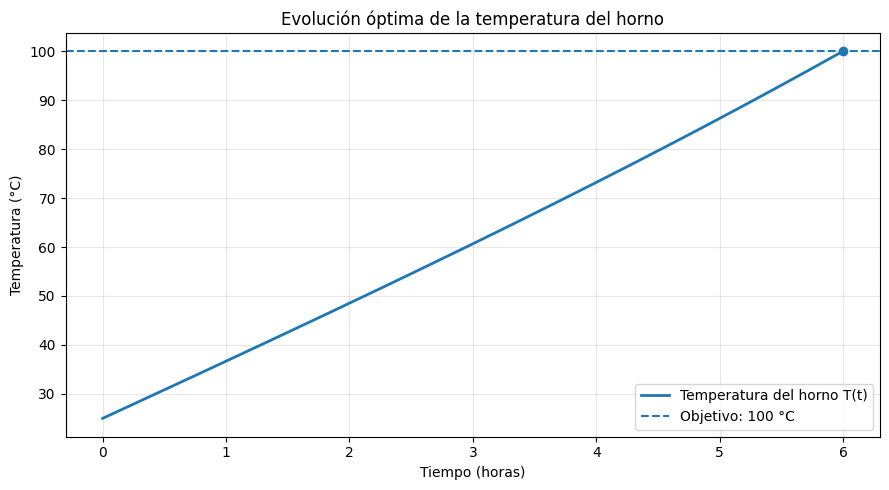

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(t, T, linewidth=2, label="Temperatura del horno T(t)")
plt.axhline(T_objetivo, linestyle="--", label="Objetivo: 100 °C")
plt.scatter([t_final], [T[-1]], zorder=3)
plt.title("Evolución óptima de la temperatura del horno")
plt.xlabel("Tiempo (horas)")
plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Grafico_Temperatura_Horno.png", dpi=200)
plt.show()

### 6. Gráfico de control $u(t)$

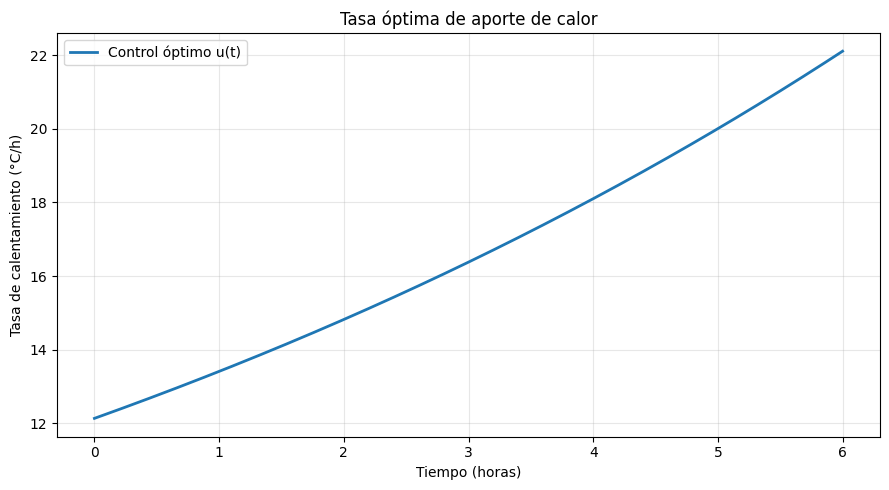

In [6]:
plt.figure(figsize=(9, 5))
plt.plot(t, u, linewidth=2, label="Control óptimo u(t)")
plt.title("Tasa óptima de aporte de calor")
plt.xlabel("Tiempo (horas)")
plt.ylabel("Tasa de calentamiento (°C/h)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Grafico_Control_Optimo.png", dpi=200)
plt.show()

### 7. Interpretación

La temperatura aumenta desde 25 °C hasta 100 °C en 6 horas. El control óptimo crece durante el período de calentamiento, compensando las pérdidas térmicas hacia el ambiente. La función $J$ es un indicador de costo definido matemáticamente, no una medida directa en kWh.

**Para el informe:** incorporar capturas del código, ambos gráficos, los valores del control y el costo mínimo. El modelo supone que no existen límites de potencia ni otras restricciones de operación.